In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, TensorDataset
import torchvision.transforms as transforms
import numpy as np
import time
from tqdm import tqdm
import clip
from medmnist import PathMNIST, INFO
import matplotlib.pyplot as plt


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cpu


In [3]:
info = INFO["pathmnist"]
print("Dataset:", info["description"])
print("Number of classes:", len(info["label"]))
print("Class labels:", info["label"])


Dataset: The PathMNIST is based on a prior study for predicting survival from colorectal cancer histology slides, providing a dataset (NCT-CRC-HE-100K) of 100,000 non-overlapping image patches from hematoxylin & eosin stained histological images, and a test dataset (CRC-VAL-HE-7K) of 7,180 image patches from a different clinical center. The dataset is comprised of 9 types of tissues, resulting in a multi-class classification task. We resize the source images of 3×224×224 into 3×28×28, and split NCT-CRC-HE-100K into training and validation set with a ratio of 9:1. The CRC-VAL-HE-7K is treated as the test set.
Number of classes: 9
Class labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


In [4]:
transform = transforms.ToTensor()

train_ds = PathMNIST(split="train", transform=transform, download=True)
val_ds   = PathMNIST(split="val",   transform=transform, download=True)
test_ds  = PathMNIST(split="test",  transform=transform, download=True)

print("Train samples:", len(train_ds))
print("Val samples:  ", len(val_ds))
print("Test samples: ", len(test_ds))


Train samples: 89996
Val samples:   10004
Test samples:  7180


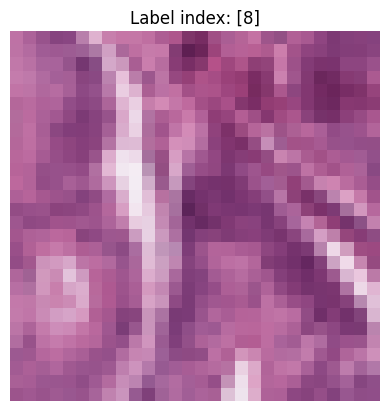

In [5]:
img, label = test_ds[0]
plt.imshow(img.permute(1,2,0))
plt.title(f"Label index: {label}")
plt.axis("off")
plt.show()


In [6]:
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device, jit=False)
clip_model.eval()

for p in clip_model.parameters():
    p.requires_grad = False

print("CLIP loaded and frozen")


CLIP loaded and frozen


In [7]:
import torchvision.transforms.functional as TF

def tensor_to_clip_input(tensor_img):
    """
    tensor_img: (3,28,28) in [0,1]
    returns: (1,3,224,224)
    """
    pil_img = TF.to_pil_image(tensor_img)
    clip_input = clip_preprocess(pil_img).unsqueeze(0).to(device)
    return clip_input


In [8]:
def extract_embeddings(dataset, model):
    embeddings = []
    labels = []

    with torch.no_grad():
        for img, label in tqdm(dataset):
            clip_input = tensor_to_clip_input(img)
            emb = model.encode_image(clip_input)
            emb = emb / emb.norm(dim=-1, keepdim=True)
            embeddings.append(emb.cpu())
            labels.append(torch.tensor(label))

    return torch.cat(embeddings), torch.stack(labels)


In [9]:
print("Extracting TRAIN embeddings...")
X_train, y_train = extract_embeddings(train_ds, clip_model)

print("Extracting VAL embeddings...")
X_val, y_val = extract_embeddings(val_ds, clip_model)

print("Extracting TEST embeddings...")
X_test, y_test = extract_embeddings(test_ds, clip_model)

print("Train:", X_train.shape)
print("Val:  ", X_val.shape)
print("Test: ", X_test.shape)


Extracting TRAIN embeddings...


IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter serve

Train: torch.Size([89996, 512])
Val:   torch.Size([10004, 512])
Test:  torch.Size([7180, 512])


In [10]:
num_classes = len(info["label"])

class LinearProbe(nn.Module):
    def __init__(self, in_dim, num_classes):
        super().__init__()
        self.fc = nn.Linear(in_dim, num_classes)

    def forward(self, x):
        return self.fc(x)


In [11]:
linear_probe = LinearProbe(
    in_dim=X_train.shape[1],
    num_classes=num_classes
).to(device)

print(linear_probe)


LinearProbe(
  (fc): Linear(in_features=512, out_features=9, bias=True)
)


In [14]:
batch_size = 128

train_loader = DataLoader(
    TensorDataset(X_train, y_train.squeeze().long()),
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val, y_val.squeeze().long()),
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test, y_test.squeeze().long()),
    batch_size=batch_size,
    shuffle=False
)


In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(linear_probe.parameters(), lr=1e-3)
epochs = 30


In [16]:
def run_epoch(loader, train=False):
    linear_probe.train() if train else linear_probe.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.set_grad_enabled(train):
        for feats, labels in loader:
            feats = feats.to(device)
            labels = labels.to(device)

            outputs = linear_probe(feats)
            loss = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


In [25]:
start_time = time.time()

for epoch in range(1, epochs + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc     = run_epoch(val_loader, train=False)

    print(
        f"Epoch [{epoch:02d}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%"
    )

total_time = time.time() - start_time
print(f"\nTotal training time: {total_time:.2f} seconds")


Epoch [01/30] | Train Loss: 0.2702 | Train Acc: 91.31% | Val Loss: 0.2652 | Val Acc: 91.41%
Epoch [02/30] | Train Loss: 0.2697 | Train Acc: 91.30% | Val Loss: 0.2648 | Val Acc: 91.34%
Epoch [03/30] | Train Loss: 0.2692 | Train Acc: 91.33% | Val Loss: 0.2641 | Val Acc: 91.41%
Epoch [04/30] | Train Loss: 0.2686 | Train Acc: 91.34% | Val Loss: 0.2636 | Val Acc: 91.42%
Epoch [05/30] | Train Loss: 0.2681 | Train Acc: 91.36% | Val Loss: 0.2632 | Val Acc: 91.46%
Epoch [06/30] | Train Loss: 0.2676 | Train Acc: 91.37% | Val Loss: 0.2627 | Val Acc: 91.44%
Epoch [07/30] | Train Loss: 0.2671 | Train Acc: 91.37% | Val Loss: 0.2624 | Val Acc: 91.48%
Epoch [08/30] | Train Loss: 0.2665 | Train Acc: 91.39% | Val Loss: 0.2619 | Val Acc: 91.49%
Epoch [09/30] | Train Loss: 0.2661 | Train Acc: 91.39% | Val Loss: 0.2615 | Val Acc: 91.51%
Epoch [10/30] | Train Loss: 0.2656 | Train Acc: 91.45% | Val Loss: 0.2608 | Val Acc: 91.56%
Epoch [11/30] | Train Loss: 0.2652 | Train Acc: 91.45% | Val Loss: 0.2606 | Val 

In [26]:
test_loss, test_acc = run_epoch(test_loader, train=False)

print("\n=========== FINAL TEST RESULT ===========")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.2f}%")
print("========================================")



=========== FINAL TEST RESULT ===========
Test Loss     : 0.3294
Test Accuracy : 88.01%


In [27]:
torch.save({
    "test_accuracy": test_acc,
    "test_loss": test_loss
}, "final_test_results.pth")


In [28]:
torch.save(
    {
        "train": {
            "embeddings": X_train,
            "labels": y_train
        },
        "val": {
            "embeddings": X_val,
            "labels": y_val
        },
        "test": {
            "embeddings": X_test,
            "labels": y_test
        }
    },
    "embeddings.pth"
)

print("✔ Embeddings saved")


✔ Embeddings saved


In [29]:
torch.save(
    linear_probe.state_dict(),
    "linear_probe.pth"
)

print("✔ Linear probe saved")


✔ Linear probe saved


In [31]:
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}


In [32]:
history["train_loss"].append(train_loss)
history["train_acc"].append(train_acc)
history["val_loss"].append(val_loss)
history["val_acc"].append(val_acc)


In [33]:
torch.save(history, "training_logs.pth")
print("✔ Training logs saved")
metadata = {
    "dataset": "PathMNIST",
    "clip_model": "ViT-B/32",
    "embedding_dim": X_train.shape[1],
    "num_classes": num_classes,
    "train_samples": len(train_ds),
    "val_samples": len(val_ds),
    "test_samples": len(test_ds),
    "epochs": epochs,
    "optimizer": "Adam",
    "learning_rate": 1e-3
}

torch.save(metadata, "metadata.pth")
print("✔ Metadata saved")


✔ Training logs saved
✔ Metadata saved


In [34]:
torch.save(
    {
        "test_loss": test_loss,
        "test_accuracy": test_acc
    },
    "final_test_results.pth"
)

print("✔ Final test results saved")


✔ Final test results saved


In [30]:
from sklearn.metrics import confusion_matrix, f1_score
import numpy as np


In [35]:
linear_probe.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for feats, labels in test_loader:
        feats = feats.to(device)
        outputs = linear_probe(feats)
        preds = outputs.argmax(dim=1)

        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

print("Total test samples:", len(y_true))


Total test samples: 7180


In [36]:
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)


Confusion Matrix:
 [[1316    1    2    0    5   11    2    0    1]
 [   6  841    0    0    0    0    0    0    0]
 [   0    1  219    0    0  102    0   14    3]
 [   0    0    3  599    0    1   12    1   18]
 [  12   39    1    0  962    2    8    5    6]
 [   0    4   17    0   26  438    0  102    5]
 [   1    0    4   17    6    0  635    0   78]
 [   0    1   47    2    9   92    7  214   49]
 [   0    0   29   40   12    4   49    4 1095]]


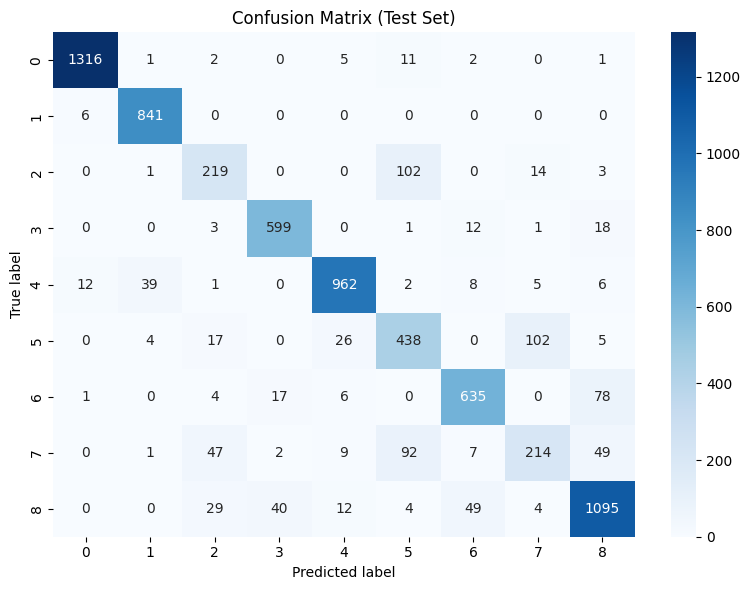

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(num_classes),
    yticklabels=range(num_classes)
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()


In [38]:
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Macro-F1 score (TEST): {macro_f1:.4f}")


Macro-F1 score (TEST): 0.8336


In [39]:
per_class_f1 = f1_score(y_true, y_pred, average=None)

for i, f1 in enumerate(per_class_f1):
    print(f"Class {i} F1-score: {f1:.4f}")


Class 0 F1-score: 0.9847
Class 1 F1-score: 0.9700
Class 2 F1-score: 0.6626
Class 3 F1-score: 0.9272
Class 4 F1-score: 0.9363
Class 5 F1-score: 0.7053
Class 6 F1-score: 0.8735
Class 7 F1-score: 0.5624
Class 8 F1-score: 0.8802


In [41]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import label_binarize
import numpy as np


In [42]:
linear_probe.eval()

all_probs = []
all_labels = []

softmax = torch.nn.Softmax(dim=1)

with torch.no_grad():
    for feats, labels in test_loader:
        feats = feats.to(device)

        outputs = linear_probe(feats)
        probs = softmax(outputs)

        all_probs.append(probs.cpu())
        all_labels.append(labels.cpu())

y_prob = torch.cat(all_probs).numpy()
y_true = torch.cat(all_labels).numpy()

print("Probability matrix shape:", y_prob.shape)


Probability matrix shape: (7180, 9)


In [44]:
y_true_bin = label_binarize(y_true, classes=np.arange(num_classes))


In [45]:
macro_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    average="macro",
    multi_class="ovr"
)

print(f"Macro ROC-AUC (OvR): {macro_auc:.4f}")


Macro ROC-AUC (OvR): 0.9872


In [46]:
micro_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    average="micro",
    multi_class="ovr"
)

print(f"Micro ROC-AUC (OvR): {micro_auc:.4f}")


Micro ROC-AUC (OvR): 0.9930


In [47]:
per_class_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    average=None,
    multi_class="ovr"
)

for i, auc in enumerate(per_class_auc):
    print(f"Class {i} ROC-AUC: {auc:.4f}")


Class 0 ROC-AUC: 0.9997
Class 1 ROC-AUC: 0.9997
Class 2 ROC-AUC: 0.9764
Class 3 ROC-AUC: 0.9986
Class 4 ROC-AUC: 0.9964
Class 5 ROC-AUC: 0.9708
Class 6 ROC-AUC: 0.9933
Class 7 ROC-AUC: 0.9589
Class 8 ROC-AUC: 0.9909


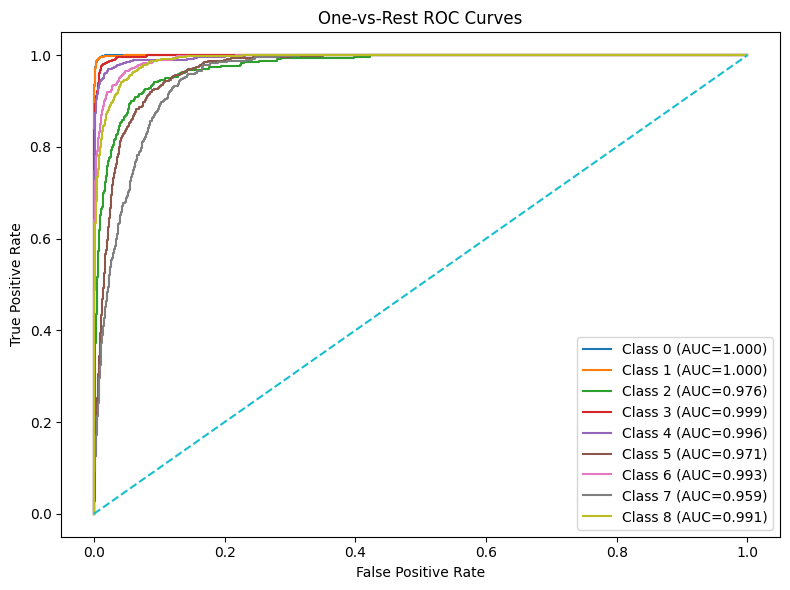

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"Class {i} (AUC={per_class_auc[i]:.3f})")

plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()


In [49]:
torch.save(
    {
        "macro_auc": macro_auc,
        "micro_auc": micro_auc,
        "per_class_auc": per_class_auc
    },
    "roc_auc_metrics.pth"
)

print("✔ ROC-AUC metrics saved")


✔ ROC-AUC metrics saved


In [50]:
classwise_acc = {}

for cls in range(num_classes):
    cls_mask = (y_true == cls)
    cls_correct = (y_pred[cls_mask] == cls).sum()
    cls_total = cls_mask.sum()

    acc = cls_correct / cls_total if cls_total > 0 else 0
    classwise_acc[cls] = acc

for cls, acc in classwise_acc.items():
    print(f"Class {cls} accuracy: {acc:.4f}")


Class 0 accuracy: 0.9836
Class 1 accuracy: 0.9929
Class 2 accuracy: 0.6460
Class 3 accuracy: 0.9448
Class 4 accuracy: 0.9295
Class 5 accuracy: 0.7399
Class 6 accuracy: 0.8570
Class 7 accuracy: 0.5083
Class 8 accuracy: 0.8881


In [51]:
classes = list(classwise_acc.keys())
accuracies = [classwise_acc[c] * 100 for c in classes]  # percentage


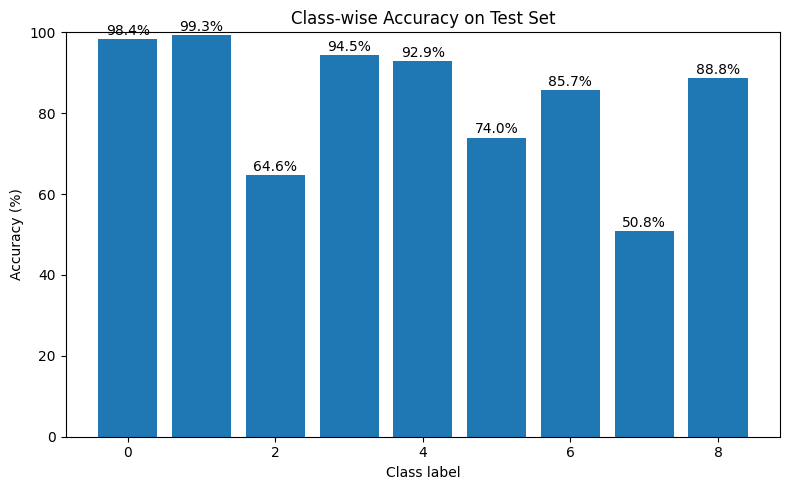

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(classes, accuracies)
plt.xlabel("Class label")
plt.ylabel("Accuracy (%)")
plt.title("Class-wise Accuracy on Test Set")
plt.ylim(0, 100)

for i, acc in enumerate(accuracies):
    plt.text(i, acc + 1, f"{acc:.1f}%", ha="center")

plt.tight_layout()
plt.show()


In [53]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_true, y_pred)
print(cm)


[[1316    1    2    0    5   11    2    0    1]
 [   6  841    0    0    0    0    0    0    0]
 [   0    1  219    0    0  102    0   14    3]
 [   0    0    3  599    0    1   12    1   18]
 [  12   39    1    0  962    2    8    5    6]
 [   0    4   17    0   26  438    0  102    5]
 [   1    0    4   17    6    0  635    0   78]
 [   0    1   47    2    9   92    7  214   49]
 [   0    0   29   40   12    4   49    4 1095]]


In [54]:
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)


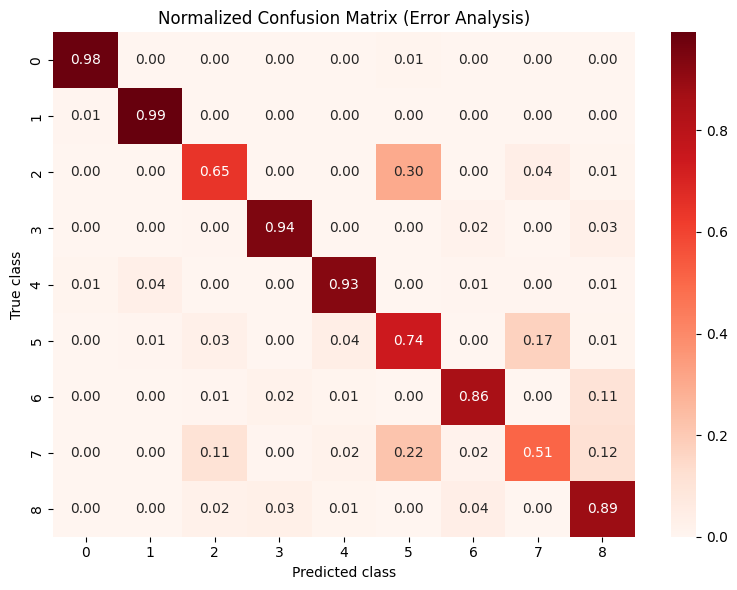

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    xticklabels=range(num_classes),
    yticklabels=range(num_classes)
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Normalized Confusion Matrix (Error Analysis)")
plt.tight_layout()
plt.show()


In [56]:
confusions = []

for true_cls in range(num_classes):
    for pred_cls in range(num_classes):
        if true_cls != pred_cls:
            confusions.append({
                "true": true_cls,
                "pred": pred_cls,
                "rate": cm_norm[true_cls, pred_cls]
            })

# Sort by highest confusion rate
confusions = sorted(confusions, key=lambda x: x["rate"], reverse=True)


In [57]:
print("Top class confusions (TEST set):\n")

for c in confusions[:10]:
    print(
        f"True class {c['true']} → Predicted as {c['pred']} "
        f"({c['rate']*100:.2f}%)"
    )


Top class confusions (TEST set):

True class 2 → Predicted as 5 (30.09%)
True class 7 → Predicted as 5 (21.85%)
True class 5 → Predicted as 7 (17.23%)
True class 7 → Predicted as 8 (11.64%)
True class 7 → Predicted as 2 (11.16%)
True class 6 → Predicted as 8 (10.53%)
True class 5 → Predicted as 4 (4.39%)
True class 2 → Predicted as 7 (4.13%)
True class 8 → Predicted as 6 (3.97%)
True class 4 → Predicted as 1 (3.77%)


In [58]:
for cls in range(num_classes):
    print(f"\nTrue class {cls} is most confused with:")
    cls_confusions = [
        c for c in confusions if c["true"] == cls and c["rate"] > 0
    ][:3]

    for c in cls_confusions:
        print(
            f"  → Class {c['pred']} ({c['rate']*100:.2f}%)"
        )



True class 0 is most confused with:
  → Class 5 (0.82%)
  → Class 4 (0.37%)
  → Class 2 (0.15%)

True class 1 is most confused with:
  → Class 0 (0.71%)

True class 2 is most confused with:
  → Class 5 (30.09%)
  → Class 7 (4.13%)
  → Class 8 (0.88%)

True class 3 is most confused with:
  → Class 8 (2.84%)
  → Class 6 (1.89%)
  → Class 2 (0.47%)

True class 4 is most confused with:
  → Class 1 (3.77%)
  → Class 0 (1.16%)
  → Class 6 (0.77%)

True class 5 is most confused with:
  → Class 7 (17.23%)
  → Class 4 (4.39%)
  → Class 2 (2.87%)

True class 6 is most confused with:
  → Class 8 (10.53%)
  → Class 3 (2.29%)
  → Class 4 (0.81%)

True class 7 is most confused with:
  → Class 5 (21.85%)
  → Class 8 (11.64%)
  → Class 2 (11.16%)

True class 8 is most confused with:
  → Class 6 (3.97%)
  → Class 3 (3.24%)
  → Class 2 (2.35%)


In [60]:
def count_per_class(dataset, num_classes):
    counts = np.zeros(num_classes, dtype=int)
    for _, label in dataset:
        counts[int(label)] += 1
    return counts


In [61]:
train_counts = count_per_class(train_ds, num_classes)
val_counts   = count_per_class(val_ds, num_classes)
test_counts  = count_per_class(test_ds, num_classes)

total_counts = train_counts + val_counts + test_counts

print("Total images per class:", total_counts)


C:\Users\Acer\AppData\Local\Temp\ipykernel_3844\2613118893.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  counts[int(label)] += 1


Total images per class: [11745 11413 11851 12191  9931 14128  9504 10867 15550]


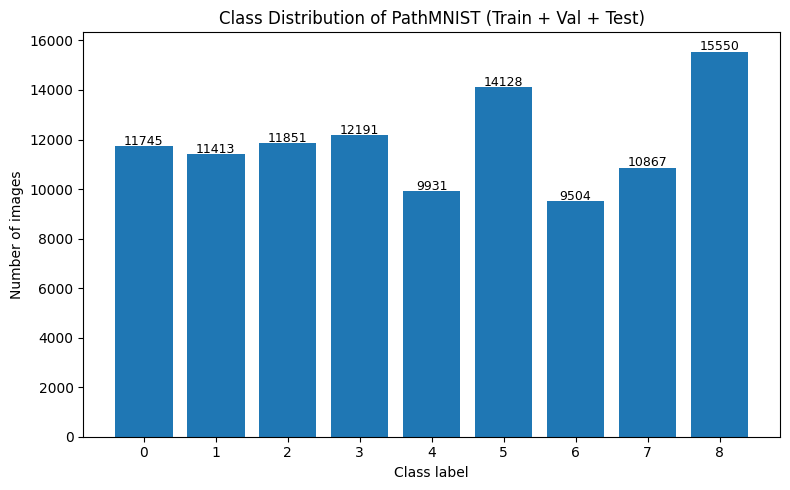

In [62]:
classes = np.arange(num_classes)

plt.figure(figsize=(8,5))
plt.bar(classes, total_counts)

plt.xlabel("Class label")
plt.ylabel("Number of images")
plt.title("Class Distribution of PathMNIST (Train + Val + Test)")
plt.xticks(classes)

# Add values on top of bars
for i, v in enumerate(total_counts):
    plt.text(i, v + 50, str(v), ha="center", fontsize=9)

plt.tight_layout()
plt.show()


In [63]:
history = torch.load("training_logs.pth")

train_loss = history["train_loss"]
val_loss   = history["val_loss"]
train_acc  = history["train_acc"]
val_acc    = history["val_acc"]


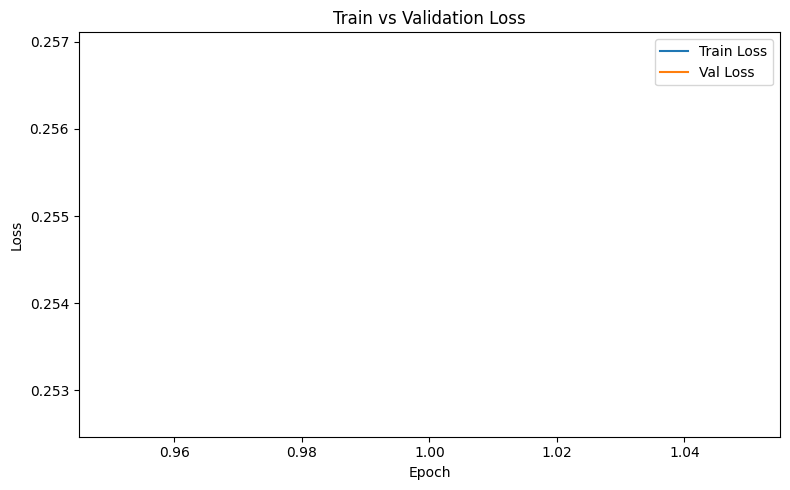

In [64]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(8,5))
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Val Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()


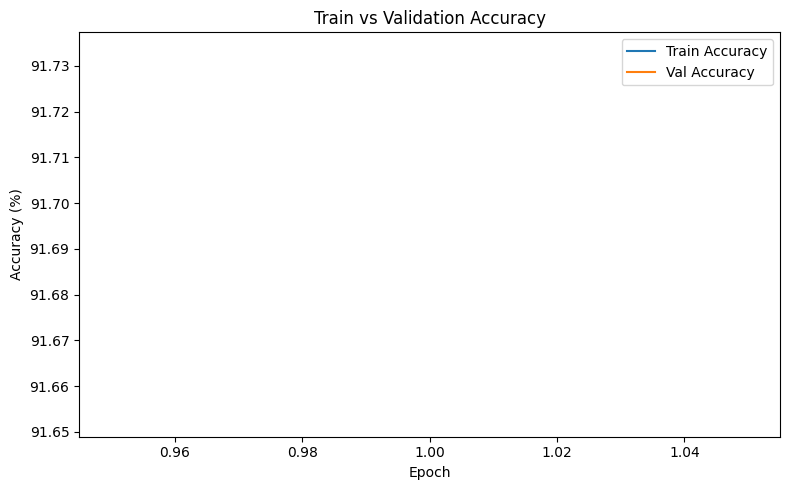

In [65]:
plt.figure(figsize=(8,5))
plt.plot(epochs, train_acc, label="Train Accuracy")
plt.plot(epochs, val_acc, label="Val Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Train vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [66]:
final_train_acc = train_acc[-1]
final_val_acc   = val_acc[-1]

acc_gap = final_train_acc - final_val_acc

print(f"Final Train Accuracy: {final_train_acc:.2f}%")
print(f"Final Val Accuracy:   {final_val_acc:.2f}%")
print(f"Accuracy Gap:         {acc_gap:.2f}%")


Final Train Accuracy: 91.65%
Final Val Accuracy:   91.73%
Accuracy Gap:         -0.08%


In [67]:
print(f"Validation Accuracy (last epoch): {final_val_acc:.2f}%")
print(f"Test Accuracy:                    {test_acc:.2f}%")
print(f"Difference (Val - Test):          {final_val_acc - test_acc:.2f}%")


Validation Accuracy (last epoch): 91.73%
Test Accuracy:                    88.01%
Difference (Val - Test):          3.72%
